# Practical 1: Uber Fare Prediction (Linear Regression vs Random Forest)

Shape: (10000, 10) | Train: (8000, 6) | Test: (2000, 6)
Linear Regression -> R2: 0.001, RMSE: 9.894
Random Forest     -> R2: 0.751, RMSE: 4.942

Sample (Actual vs Pred):
    Actual     LR     RF
0     7.3  11.44   8.21
1    11.0  11.10   8.02
2    19.5  11.09  12.10
3     9.5  11.09   8.21
4     9.0  11.19   9.22


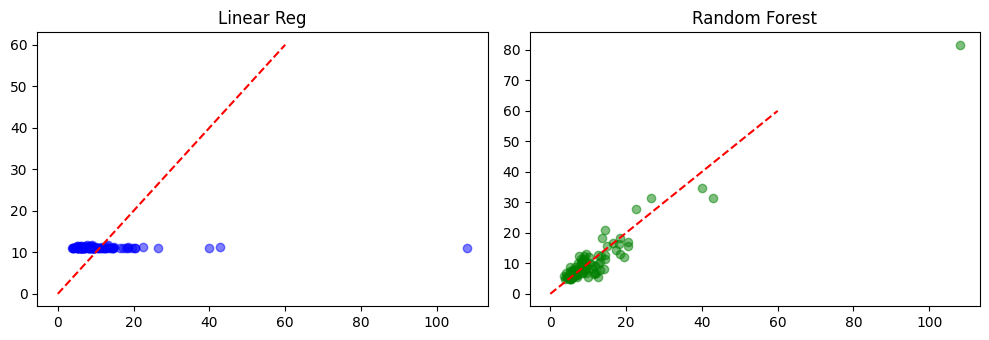

In [14]:
# Practical 1: Uber Fare Prediction
import os, numpy as np, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import r2_score, mean_squared_error

# 1. Load, engineer distance & split
path = "uber.csv" if os.path.exists("uber.csv") else "Practical 1/uber.csv"
df = pd.read_csv(path).dropna().sample(10000, random_state=42)
df["dist"] = np.hypot(df["dropoff_longitude"] - df["pickup_longitude"], df["dropoff_latitude"] - df["pickup_latitude"]) * 111
X = df[["pickup_longitude", "pickup_latitude", "dropoff_longitude", "dropoff_latitude", "passenger_count", "dist"]]
y = df["fare_amount"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=42)

# 2. Train & Predict
lr, rf = LinearRegression().fit(X_tr, y_tr), RandomForestRegressor(30, max_depth=8, random_state=42).fit(X_tr, y_tr)
p_lr, p_rf = lr.predict(X_te), rf.predict(X_te)

# 3. Output
print(f"Shape: {df.shape} | Train: {X_tr.shape} | Test: {X_te.shape}")
print(f"Linear Regression -> R2: {r2_score(y_te, p_lr):.3f}, RMSE: {np.sqrt(mean_squared_error(y_te, p_lr)):.3f}")
print(f"Random Forest     -> R2: {r2_score(y_te, p_rf):.3f}, RMSE: {np.sqrt(mean_squared_error(y_te, p_rf)):.3f}")
print("\nSample (Actual vs Pred):\n", pd.DataFrame({"Actual": y_te.values[:5], "LR": p_lr[:5].round(2), "RF": p_rf[:5].round(2)}))

# 4. Plots
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.scatter(y_te[:100], p_lr[:100], alpha=0.5, color="b"); ax1.plot([0, 60], [0, 60], "--r"); ax1.set_title("Linear Reg")
ax2.scatter(y_te[:100], p_rf[:100], alpha=0.5, color="g"); ax2.plot([0, 60], [0, 60], "--r"); ax2.set_title("Random Forest")
plt.tight_layout(); plt.show()


# Practical 2: K-Means Clustering & Elbow Method

Shape: (2823, 5) | Silhouette Score: 0.351
Clusters:
 Cluster
2    996
0    975
1    852


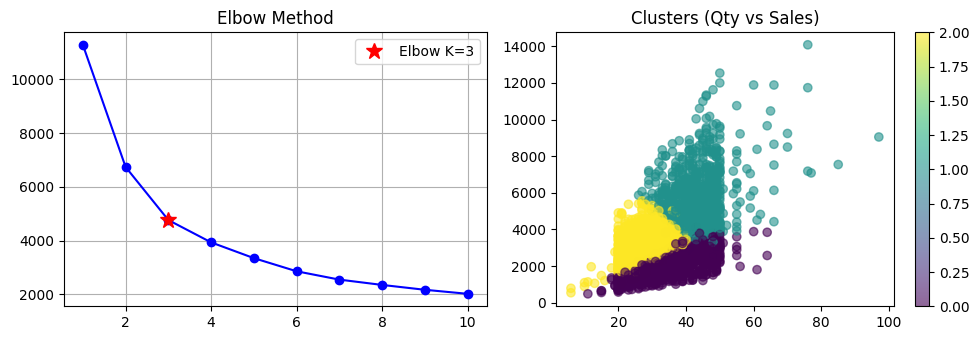

In [15]:
# Practical 2: K-Means Clustering & Elbow Method
import os, pandas as pd, matplotlib.pyplot as plt
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import silhouette_score

X = pd.read_csv("sales_data_sample.csv" if os.path.exists("sales_data_sample.csv") else "Practical 2/sales_data_sample.csv", encoding="unicode_escape")[["QUANTITYORDERED", "PRICEEACH", "SALES", "MSRP"]].dropna()
X_s = StandardScaler().fit_transform(X)

wcss = [KMeans(k, random_state=42, n_init=10).fit(X_s).inertia_ for k in range(1, 11)]
km = KMeans(3, random_state=42, n_init=10)
X["Cluster"] = km.fit_predict(X_s)

print(f"Shape: {X.shape} | Silhouette Score: {silhouette_score(X_s, X['Cluster']):.3f}")
print("Clusters:\n", X["Cluster"].value_counts().to_string())

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(range(1, 11), wcss, "-ob"); ax1.plot(3, wcss[2], "*r", markersize=12, label="Elbow K=3")
ax1.set_title("Elbow Method"); ax1.legend(); ax1.grid(True)
scatter = ax2.scatter(X["QUANTITYORDERED"], X["SALES"], c=X["Cluster"], cmap="viridis", alpha=0.6)
ax2.set_title("Clusters (Qty vs Sales)"); plt.colorbar(scatter, ax=ax2)
plt.tight_layout(); plt.show()


# Practical 3: K-Nearest Neighbors (KNN) Classification

Shape: (768, 9) | Accuracy: 70.78%

              precision    recall  f1-score   support

    Negative       0.76      0.81      0.78       100
    Positive       0.60      0.52      0.55        54

    accuracy                           0.71       154
   macro avg       0.68      0.66      0.67       154
weighted avg       0.70      0.71      0.70       154



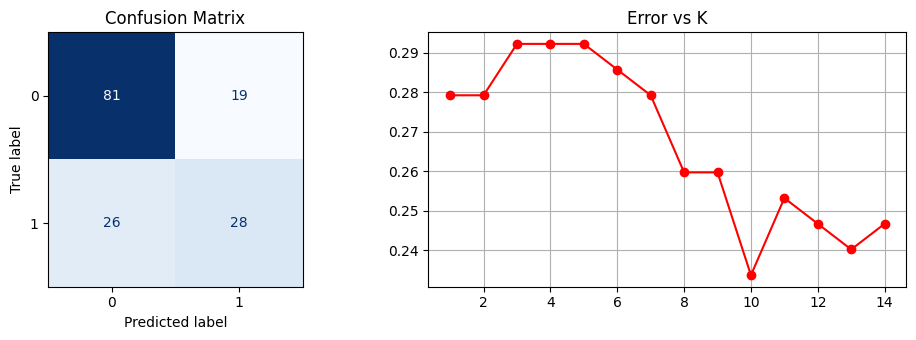

In [16]:
# Practical 3: KNN Classification
import os, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay

df = pd.read_csv("diabetes.csv" if os.path.exists("diabetes.csv") else "Practical 3/diabetes.csv")
for c in ["Glucose", "BloodPressure", "BMI"]: df[c] = df[c].replace(0, df[df[c] != 0][c].median())
X_tr, X_te, y_tr, y_te = train_test_split(df.drop("Outcome", axis=1), df["Outcome"], test_size=0.2, random_state=42, stratify=df["Outcome"])

scaler = StandardScaler()
X_tr, X_te = scaler.fit_transform(X_tr), scaler.transform(X_te)
knn = KNeighborsClassifier(5).fit(X_tr, y_tr)
y_pr = knn.predict(X_te)

print(f"Shape: {df.shape} | Accuracy: {accuracy_score(y_te, y_pr)*100:.2f}%\n")
print(classification_report(y_te, y_pr, target_names=["Negative", "Positive"]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ConfusionMatrixDisplay.from_predictions(y_te, y_pr, cmap="Blues", ax=ax1, colorbar=False); ax1.set_title("Confusion Matrix")
ax2.plot(range(1, 15), [1 - accuracy_score(y_te, KNeighborsClassifier(k).fit(X_tr, y_tr).predict(X_te)) for k in range(1, 15)], "-or")
ax2.set_title("Error vs K"); ax2.grid(True)
plt.tight_layout(); plt.show()


# Practical 4: Artificial Neural Network (MLPClassifier)

Data: (10000, 12) | Accuracy: 87.25% | Epochs: 223

              precision    recall  f1-score   support

    Retained       0.88      0.97      0.92      1593
     Churned       0.82      0.48      0.60       407

    accuracy                           0.87      2000
   macro avg       0.85      0.73      0.76      2000
weighted avg       0.87      0.87      0.86      2000



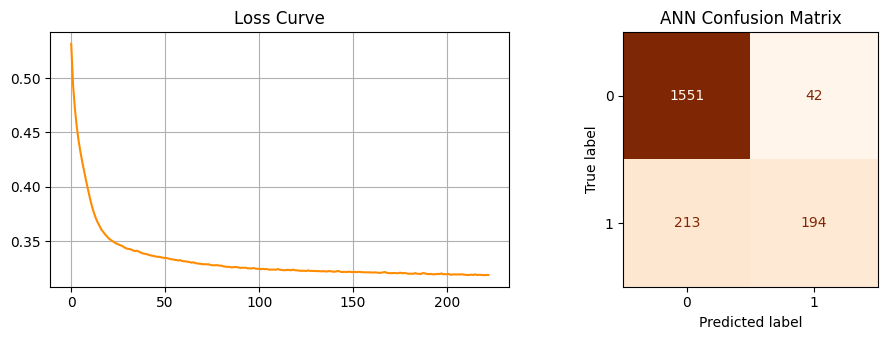

In [17]:
# Practical 4: Artificial Neural Network (MLP)
import os, warnings, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neural_network import MLPClassifier
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
warnings.filterwarnings("ignore")

df = pd.read_csv("Churn_Modelling.csv" if os.path.exists("Churn_Modelling.csv") else "Practical 4/Churn_Modelling.csv").drop(["RowNumber", "CustomerId", "Surname"], axis=1)
df = pd.get_dummies(df, columns=["Geography", "Gender"], drop_first=True)
X_tr, X_te, y_tr, y_te = train_test_split(df.drop("Exited", axis=1), df["Exited"], test_size=0.2, random_state=42, stratify=df["Exited"])

scaler = StandardScaler()
X_tr, X_te = scaler.fit_transform(X_tr), scaler.transform(X_te)
mlp = MLPClassifier((16, 8), max_iter=250, random_state=42).fit(X_tr, y_tr)
y_pr = mlp.predict(X_te)

print(f"Data: {df.shape} | Accuracy: {accuracy_score(y_te, y_pr)*100:.2f}% | Epochs: {mlp.n_iter_}\n")
print(classification_report(y_te, y_pr, target_names=["Retained", "Churned"]))

fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(10, 3.5))
ax1.plot(mlp.loss_curve_, color="darkorange"); ax1.set_title("Loss Curve"); ax1.grid(True)
ConfusionMatrixDisplay.from_predictions(y_te, y_pr, cmap="Oranges", ax=ax2, colorbar=False); ax2.set_title("ANN Confusion Matrix")
plt.tight_layout(); plt.show()


# Practical 5: Spam Detection (KNN vs SVM)

Data: (5172, 3002) | KNN Acc: 83.38% | SVM Acc: 93.04%

SVM Classification Report:
               precision    recall  f1-score   support

         Ham       0.98      0.92      0.95       735
        Spam       0.83      0.96      0.89       300

    accuracy                           0.93      1035
   macro avg       0.91      0.94      0.92      1035
weighted avg       0.94      0.93      0.93      1035



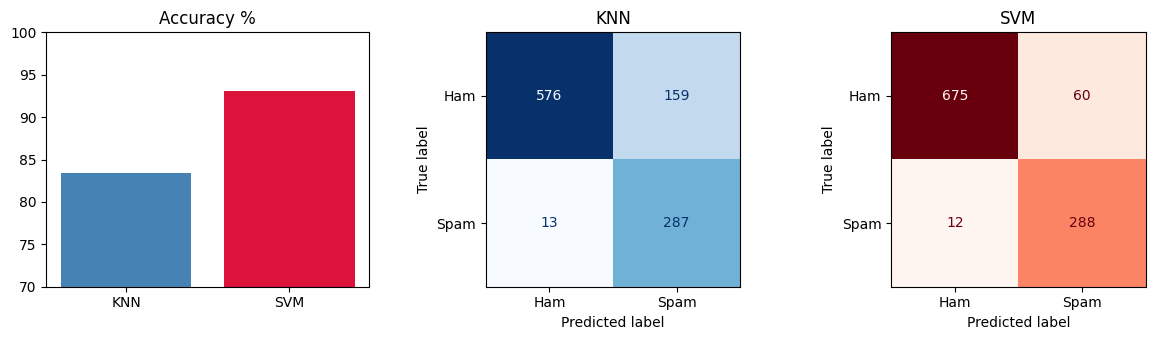

In [18]:
# Practical 5: Spam Detection (KNN vs SVM)
import os, warnings, pandas as pd, matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.svm import LinearSVC
from sklearn.metrics import accuracy_score, classification_report, ConfusionMatrixDisplay
warnings.filterwarnings("ignore")

df = pd.read_csv("emails.csv" if os.path.exists("emails.csv") else "Practical 5/emails.csv")
X_tr, X_te, y_tr, y_te = train_test_split(df.drop(["Email No.", "Prediction"], axis=1), df["Prediction"], test_size=0.2, random_state=42, stratify=df["Prediction"])

scaler = StandardScaler()
X_tr, X_te = scaler.fit_transform(X_tr), scaler.transform(X_te)
p_knn = KNeighborsClassifier(5).fit(X_tr, y_tr).predict(X_te)
p_svm = LinearSVC(dual=False, random_state=42).fit(X_tr, y_tr).predict(X_te)

a_knn, a_svm = accuracy_score(y_te, p_knn), accuracy_score(y_te, p_svm)
print(f"Data: {df.shape} | KNN Acc: {a_knn*100:.2f}% | SVM Acc: {a_svm*100:.2f}%\n")
print("SVM Classification Report:\n", classification_report(y_te, p_svm, target_names=["Ham", "Spam"]))

fig, (ax1, ax2, ax3) = plt.subplots(1, 3, figsize=(12, 3.5))
ax1.bar(["KNN", "SVM"], [a_knn*100, a_svm*100], color=["steelblue", "crimson"]); ax1.set_ylim(70, 100); ax1.set_title("Accuracy %")
ConfusionMatrixDisplay.from_predictions(y_te, p_knn, display_labels=["Ham", "Spam"], cmap="Blues", ax=ax2, colorbar=False); ax2.set_title("KNN")
ConfusionMatrixDisplay.from_predictions(y_te, p_svm, display_labels=["Ham", "Spam"], cmap="Reds", ax=ax3, colorbar=False); ax3.set_title("SVM")
plt.tight_layout(); plt.show()
